<a href="https://colab.research.google.com/github/ilyak0n/image_processing/blob/main/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%964._%D0%A0%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D1%81_%D1%80%D0%B0%D1%81%D1%82%D1%80%D0%BE%D0%B2%D1%8B%D0%BC%D0%B8_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D0%BC%D0%B8_%D0%B2_Rasterio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №5. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

### **Задание 1. Чтение и исследование растровых данных**



In [2]:
import rasterio
import rasterio.plot
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


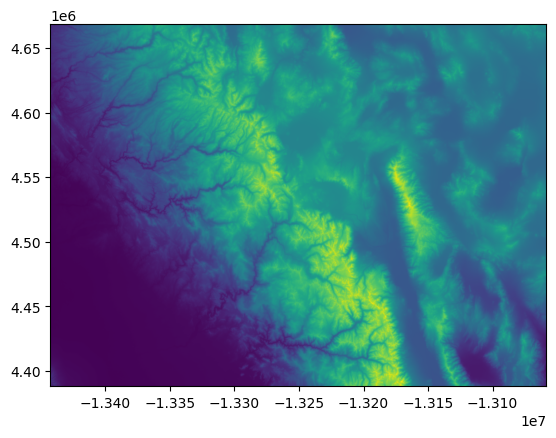

<Axes: >

In [ ]:
raster_path = ("https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif")

src = rasterio.open(raster_path)

rasterio.plot.show((src))

2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [ ]:
src.meta

{'driver': 'GTiff',
 'dtype': 'int16',
 'nodata': None,
 'width': 4269,
 'height': 3113,
 'count': 1,
 'crs': CRS.from_wkt('PROJCS["WGS 84 / Pseudo-Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Mercator_1SP"],PARAMETER["central_meridian",0],PARAMETER["scale_factor",1],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],EXTENSION["PROJ4","+proj=merc +a=6378137 +b=6378137 +lat_ts=0 +lon_0=0 +x_0=0 +y_0=0 +k=1 +units=m +nadgrids=@null +wktext +no_defs"],AUTHORITY["EPSG","3857"]]'),
 'transform': Affine(90.0, 0.0, -13442488.3428,
        0.0, -89.99579177642138, 4668371.5775)}

3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [ ]:
print(src.width)
print(src.height)
print(src.dtypes)

4269
3113
('int16',)


---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


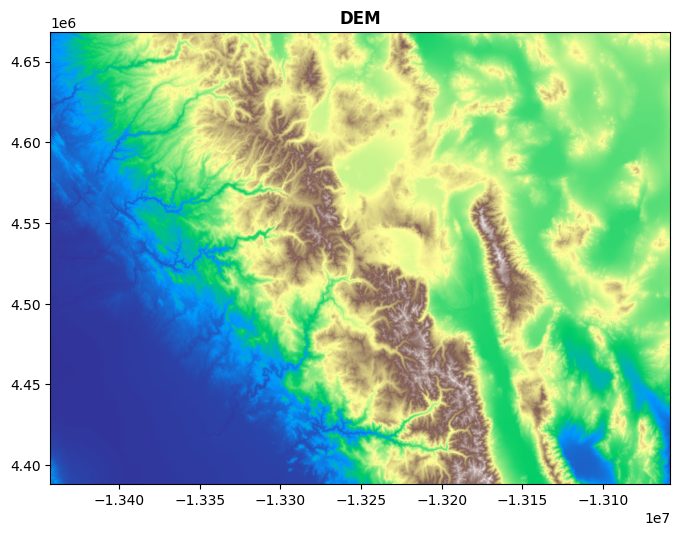

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))

rasterio.plot.show(src, cmap='terrain', ax=ax, title='DEM')
plt.show()

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


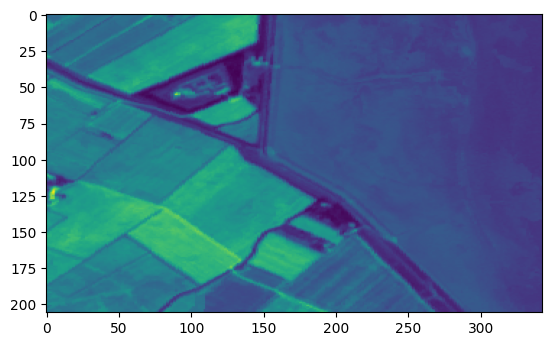

In [15]:
landsat_path = ("https://github.com/opengeos/datasets/releases/download/raster/cog.tif")

src1 = rasterio.open(landsat_path)

plt.imshow(src1.read(1), cmap='viridis')
plt.show()

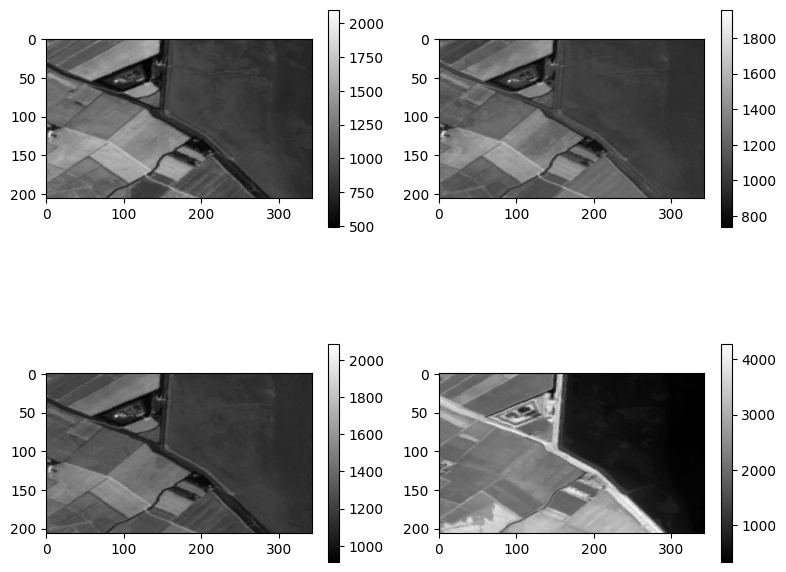

In [16]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
axes = axes.flatten()

for band in range(1, src1.count+1):
  data = src1.read(band)
  ax = axes[band - 1]
  im = ax.imshow(data, cmap='gray')
  fig.colorbar(im, ax=ax, shrink=0.5)
plt.tight_layout()
plt.show()

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

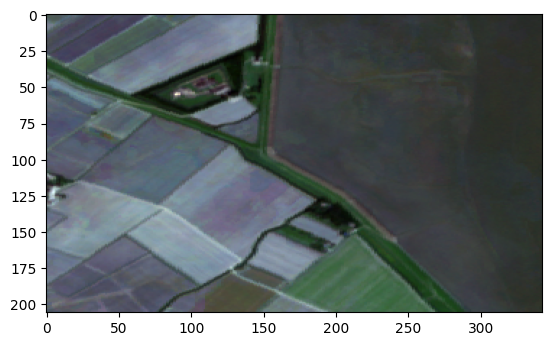

In [21]:
import cv2 as cv
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

b = normalize(src1.read(1))
g = normalize(src1.read(2))
r = normalize(src1.read(3))
rgb = np.dstack((r, g, b))

plt.imshow(rgb)
plt.show()

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [3]:
landsat_path = ("https://github.com/opengeos/datasets/releases/download/raster/cog.tif")

src = rasterio.open(landsat_path)

data = src.read()

subset = data[:, 50:200, 50:150]

subset.shape

(4, 150, 100)

2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

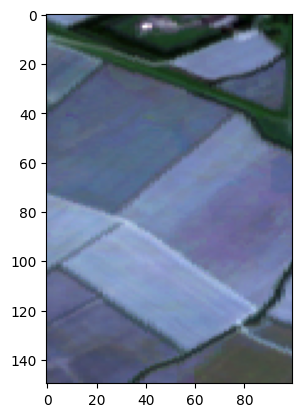

(150, 100, 3)

In [4]:
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm

b = normalize(subset[0])
g = normalize(subset[1])
r = normalize(subset[2])

rgb_subset = np.dstack((r, g, b))

plt.imshow(rgb_subset)
plt.show()
rgb_subset.shape

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [6]:
with rasterio.open(
    "clipped_multispectral.tiff",
    "w",
    driver="GTiff",
    height=subset.shape[1],
    width=subset.shape[2],
    count=subset.shape[0],
    dtype=subset.dtype,
    crs=src.crs,
    compress="lzw"
) as dst:
  dst.write(subset)

---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [28]:
raster_path = ("https://github.com/opengeos/datasets/releases/download/raster/cog.tif")
src = rasterio.open(raster_path)

green = src.read(2)
nir = src.read(4)

2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [29]:
ndwi = (green - nir)/(green + nir)
ndwi = ndwi.clip(-1, 1)

3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


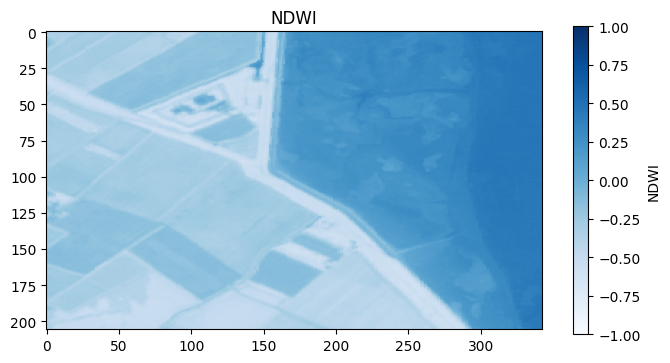

In [30]:
plt.figure(figsize=(8,8))
plt.imshow(ndwi, cmap="Blues", vmin=-1, vmax=1)
plt.colorbar(label='NDWI', shrink=0.5)
plt.title('NDWI')
plt.show()



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [31]:
with rasterio.open(raster_path) as src:
  profile = src.profile

profile.update(dtype=rasterio.float32, count=1, compress='lzw')

with rasterio.open('ndwi.tif', "w", **profile) as dst:
  dst.write(ndwi, 1)

---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [45]:
from rasterio.warp import reproject, calculate_default_transform, Resampling

raster_path = "https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif"
dst_crs = "EPSG:4326"

with rasterio.open(raster_path) as src:
  transform, width, height = calculate_default_transform(
      src.crs, dst_crs, src.width, src.height, *src.bounds
  )

  profile = src.profile
  profile.update(crs=dst_crs, transform=transform, width=width, height=height)

  reprojected = np.zeros((src.count, height, width), dtype=profile['dtype'])

  for i in range(1, src.count+1):
    reproject(
        source=rasterio.band(src, i),
        destination=reprojected[i-1],
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=transform,
        dst_crs=dst_crs,
        resampling=Resampling.nearest,
    )

2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


In [46]:
with rasterio.open("reprojected_dem.tif", "w", **profile) as dst:
  dst.write(reprojected)

3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

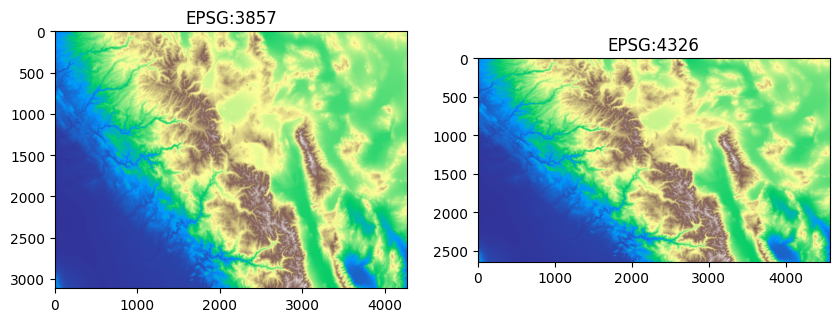

In [48]:
reprojected_file = rasterio.open("reprojected_dem.tif")
src = rasterio.open(raster_path)

plt.figure(figsize=(10,8))

plt.subplot(1,2,1)
plt.imshow(src.read(1), cmap='terrain')
plt.title(src.crs)

plt.subplot(1,2,2)
plt.imshow(reprojected_file.read(1), cmap='terrain')
plt.title(reprojected_file.crs)

plt.show()

---